# 3.0 - Entrenamiento y torneo de modelos

Entrena y compara modelos de regresión para predecir `SalePrice`:

- **Torneo de 6 modelos:** regresiones (Ridge, Lasso, ElasticNet), ensambles (Random Forest, Gradient Boosting) y una red neuronal (MLP).
- **Optimización de hiperparámetros** con `GridSearchCV` y validación cruzada `KFold` de 10 folds, optimizando el **RMSE real en dólares**.
- **Comparación final en el set de validación** (nunca usado en el entrenamiento ni en la búsqueda) con el RMSE real y el RMSE normalizado al rango.

**Prevención de fuga de datos y sobreajuste:**

- El pipeline de feature engineering (`models/pipeline_fe.joblib`) se usa **sin ajustar** y dentro de cada modelo, de modo que en cada fold de la CV se reajusta solo con los datos de entrenamiento de ese fold.
- El set de validación solo se usa una vez, al final, para el torneo.
- Las rejillas incluyen hiperparámetros de regularización (penalizaciones, profundidad, hojas mínimas, *subsample*, *early stopping*).

## Configuración

Importa las librerías y define rutas, semilla y constantes de la validación cruzada.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.ticker import FuncFormatter
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 200)

PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"
MODELS_DIR = PROJ_ROOT / "models"

RANDOM_STATE = 42
N_FOLDS = 10

with open(PROJ_ROOT / "pipeline_config.yaml") as f:
    MODEL_FEATURES = yaml.safe_load(f)["MODEL_FEATURES"]

formato_dolares = FuncFormatter(lambda x, _: f"${x / 1000:,.0f}k")

## Carga de datos y reconstrucción del split

Para que el feature engineering se reajuste dentro de cada fold, el modelo recibe los datos **crudos**. Se reconstruye exactamente el mismo split del notebook 2.0 a partir de los `Id` guardados en `train_fe.csv` y `valid_fe.csv` (no se vuelve a sortear), y se aplica la misma eliminación de las 2 casas atípicas.

El target es `log_SalePrice = log1p(SalePrice)`, igual que en el notebook 2.0.

In [2]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv", index_col="Id")
outliers_extremos = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)
train = train.loc[~outliers_extremos]

ids_train = pd.read_csv(PROCESSED_DATA_DIR / "train_fe.csv", usecols=["Id"])["Id"]
ids_valid = pd.read_csv(PROCESSED_DATA_DIR / "valid_fe.csv", usecols=["Id"])["Id"]

X_train = train.loc[ids_train, MODEL_FEATURES]
X_valid = train.loc[ids_valid, MODEL_FEATURES]
y_train = np.log1p(train.loc[ids_train, "SalePrice"]).rename("log_SalePrice")
y_valid = np.log1p(train.loc[ids_valid, "SalePrice"]).rename("log_SalePrice")

assert set(ids_train).isdisjoint(ids_valid)

print(f"X_train: {X_train.shape}")
print(f"X_valid: {X_valid.shape}")

X_train: (1166, 30)
X_valid: (292, 30)


## Pipeline de feature engineering sin ajustar

Carga `pipeline_fe.joblib` y lo clona con `sklearn.base.clone`, que conserva la configuración de cada paso pero descarta todo lo aprendido (medianas, límites de capping, lambdas, medias y desviaciones). Como verificación, se reajusta con `X_train` y se comprueba que reproduce `train_fe.csv`.

In [3]:
pipeline_fe = clone(joblib.load(MODELS_DIR / "pipeline_fe.joblib"))

train_fe = pd.read_csv(PROCESSED_DATA_DIR / "train_fe.csv", index_col="Id").drop(columns="log_SalePrice")
X_train_fe_check = clone(pipeline_fe).fit_transform(X_train)
assert np.allclose(X_train_fe_check.to_numpy(dtype=float), train_fe.to_numpy(dtype=float))

print("El pipeline sin ajustar reproduce train_fe.csv")
pipeline_fe

El pipeline sin ajustar reproduce train_fe.csv


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('descartar_faltantes', ...), ('imputar_mediana', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features_to_drop,['FireplaceQu']
,variables,"['GrLivArea', 'GarageArea', ...]"
,imputation_method,'median'
,variables,"['GarageYrBlt', 'LotFrontage']"
,random_state,42
,seed,'general'
,seeding_method,'add'


## Validación cruzada y métrica

- **KFold:** 10 folds con `shuffle=True` y semilla fija, los mismos para todos los modelos para que la comparación sea justa.
- **Métrica de la búsqueda:** RMSE real en dólares. Los modelos predicen `log_SalePrice`; el scorer revierte con `np.expm1` tanto el target como la predicción antes de calcular el RMSE. Se define con `greater_is_better=False`, por lo que `GridSearchCV` reporta su valor negativo.

In [4]:
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def rmse_real(y_log, pred_log):
    """RMSE en dólares a partir de target y predicción en escala log1p."""
    return root_mean_squared_error(np.expm1(y_log), np.expm1(pred_log))


scorer_rmse_real = make_scorer(rmse_real, greater_is_better=False)

## Modelos y rejillas de hiperparámetros

Cada modelo es un `Pipeline` con el feature engineering (`fe`) seguido del estimador (`modelo`), así ambos se ajustan juntos en cada fold. Cada rejilla tiene al menos 3 configuraciones:

| Modelo | Tipo | Hiperparámetros explorados |
|---|---|---|
| Ridge | Regresión L2 | `alpha` |
| Lasso | Regresión L1 | `alpha` |
| ElasticNet | Regresión L1 + L2 | `alpha`, `l1_ratio` |
| Random Forest | Ensamble (bagging) | `max_depth`, `min_samples_leaf`, `max_features` |
| Gradient Boosting | Ensamble (boosting) | `learning_rate`, `max_depth`, `n_estimators` (con `subsample=0.8`) |
| MLP | Red neuronal | `hidden_layer_sizes`, `alpha` (con `early_stopping`) |

La MLP se envuelve en `TransformedTargetRegressor` con `StandardScaler` para estandarizar el target durante el entrenamiento (las redes convergen mejor); sus predicciones vuelven automáticamente a la escala `log_SalePrice`, y el escalador del target también se ajusta dentro de cada fold.

In [5]:
mlp = TransformedTargetRegressor(
    regressor=MLPRegressor(
        early_stopping=True, max_iter=2000, learning_rate_init=1e-3, random_state=RANDOM_STATE
    ),
    transformer=StandardScaler(),
)

modelos = {
    "Ridge": (
        Ridge(),
        {"modelo__alpha": [0.1, 1, 3, 10, 30, 100]},
    ),
    "Lasso": (
        Lasso(max_iter=50_000),
        {"modelo__alpha": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]},
    ),
    "ElasticNet": (
        ElasticNet(max_iter=50_000),
        {"modelo__alpha": [1e-4, 1e-3, 1e-2], "modelo__l1_ratio": [0.2, 0.5, 0.8]},
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "modelo__max_depth": [None, 15],
            "modelo__min_samples_leaf": [1, 3],
            "modelo__max_features": [0.33, 1.0],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(subsample=0.8, random_state=RANDOM_STATE),
        {
            "modelo__learning_rate": [0.03, 0.1],
            "modelo__max_depth": [2, 3],
            "modelo__n_estimators": [300, 800],
        },
    ),
    "MLP": (
        mlp,
        {
            "modelo__regressor__hidden_layer_sizes": [(64,), (128, 64)],
            "modelo__regressor__alpha": [1e-3, 1e-1, 1.0],
        },
    ),
}

pd.DataFrame({
    "configuraciones": {
        nombre: int(np.prod([len(v) for v in grid.values()])) for nombre, (_, grid) in modelos.items()
    }
})

,configuraciones
Ridge,6
Lasso,5
ElasticNet,9
Random Forest,8
Gradient Boosting,8
MLP,6


## Optimización de hiperparámetros (GridSearchCV)

Para cada modelo ejecuta `GridSearchCV` sobre `X_train` con los 10 folds y el scorer de RMSE real. Al terminar, `refit=True` reentrena la mejor configuración con todo `X_train`. Se guarda también el RMSE de train por fold (`return_train_score`) como referencia de sobreajuste. Esta celda puede tardar unos minutos.

In [6]:
busquedas = {}
for nombre, (estimador, grid) in modelos.items():
    busqueda = GridSearchCV(
        Pipeline([("fe", clone(pipeline_fe)), ("modelo", estimador)]),
        param_grid=grid,
        scoring=scorer_rmse_real,
        cv=cv,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_train, y_train)
    busquedas[nombre] = busqueda
    print(f"{nombre:<18} RMSE CV = ${-busqueda.best_score_:,.0f}  |  {busqueda.best_params_}")

Ridge              RMSE CV = $24,723  |  {'modelo__alpha': 3}
Lasso              RMSE CV = $24,766  |  {'modelo__alpha': 0.0001}
ElasticNet         RMSE CV = $24,745  |  {'modelo__alpha': 0.0001, 'modelo__l1_ratio': 0.2}
Random Forest      RMSE CV = $26,658  |  {'modelo__max_depth': 15, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
Gradient Boosting  RMSE CV = $24,970  |  {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
MLP                RMSE CV = $24,657  |  {'modelo__regressor__alpha': 1.0, 'modelo__regressor__hidden_layer_sizes': (128, 64)}


## Resultados de la búsqueda por modelo

Muestra todas las configuraciones probadas de cada modelo, ordenadas por RMSE de CV (en dólares), con su dispersión entre folds y el RMSE de train. Una brecha grande entre train y CV indica que esa configuración sobreajusta.

In [7]:
for nombre, busqueda in busquedas.items():
    res = pd.DataFrame(busqueda.cv_results_)
    tabla = pd.DataFrame({
        "params": res["params"].apply(lambda p: {k.replace("modelo__", "").replace("regressor__", ""): v for k, v in p.items()}),
        "rmse_cv": -res["mean_test_score"],
        "std_cv": res["std_test_score"],
        "rmse_train": -res["mean_train_score"],
    }).sort_values("rmse_cv")
    print(f"\n=== {nombre} ===")
    for col in ["rmse_cv", "std_cv", "rmse_train"]:
        tabla[col] = tabla[col].map("${:,.0f}".format)
    display(tabla.reset_index(drop=True))


=== Ridge ===


,params,rmse_cv,std_cv,rmse_train
0,{'alpha': 3},"$24,723","$4,561","$23,991"
1,{'alpha': 1},"$24,724","$4,571","$23,949"
2,{'alpha': 0.1},"$24,745","$4,580","$23,942"
3,{'alpha': 10},"$24,805","$4,557","$24,174"
4,{'alpha': 30},"$25,023","$4,577","$24,554"
5,{'alpha': 100},"$25,480","$4,737","$25,255"



=== Lasso ===


,params,rmse_cv,std_cv,rmse_train
0,{'alpha': 0.0001},"$24,766","$4,599","$23,984"
1,{'alpha': 0.0003},"$24,902","$4,634","$24,140"
2,{'alpha': 0.001},"$25,496","$4,817","$24,960"
3,{'alpha': 0.003},"$25,910","$4,926","$25,704"
4,{'alpha': 0.01},"$26,734","$5,800","$26,825"



=== ElasticNet ===


,params,rmse_cv,std_cv,rmse_train
0,"{'alpha': 0.0001, 'l1_ratio': 0.2}","$24,745","$4,585","$23,947"
1,"{'alpha': 0.0001, 'l1_ratio': 0.5}","$24,749","$4,590","$23,958"
2,"{'alpha': 0.0001, 'l1_ratio': 0.8}","$24,757","$4,595","$23,972"
3,"{'alpha': 0.001, 'l1_ratio': 0.2}","$24,835","$4,612","$24,080"
4,"{'alpha': 0.001, 'l1_ratio': 0.5}","$25,092","$4,682","$24,369"
5,"{'alpha': 0.001, 'l1_ratio': 0.8}","$25,387","$4,789","$24,736"
6,"{'alpha': 0.01, 'l1_ratio': 0.2}","$25,702","$4,855","$25,496"
7,"{'alpha': 0.01, 'l1_ratio': 0.5}","$26,168","$5,138","$26,123"
8,"{'alpha': 0.01, 'l1_ratio': 0.8}","$26,499","$5,554","$26,527"


... (2 outputs left out)


=== Gradient Boosting ===


,params,rmse_cv,std_cv,rmse_train
0,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300}","$24,970","$3,470","$16,535"
1,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 800}","$25,019","$3,786","$11,255"
2,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 800}","$25,079","$3,591","$16,758"
3,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}","$26,132","$3,984","$15,792"
4,"{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}","$26,180","$4,075","$20,923"
5,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}","$26,213","$3,745","$10,133"
6,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 800}","$26,812","$4,491","$10,485"
7,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 800}","$26,862","$3,995","$4,366"



=== MLP ===


,params,rmse_cv,std_cv,rmse_train
0,"{'alpha': 1.0, 'hidden_layer_sizes': (128, 64)}","$24,657","$3,815","$19,228"
1,"{'alpha': 1.0, 'hidden_layer_sizes': (64,)}","$24,947","$3,607","$19,970"
2,"{'alpha': 0.1, 'hidden_layer_sizes': (128, 64)}","$24,984","$3,058","$17,921"
3,"{'alpha': 0.001, 'hidden_layer_sizes': (128, 64)}","$24,993","$2,976","$17,995"
4,"{'alpha': 0.1, 'hidden_layer_sizes': (64,)}","$25,307","$3,476","$18,801"
5,"{'alpha': 0.001, 'hidden_layer_sizes': (64,)}","$25,485","$3,324","$18,690"


## Torneo: evaluación en el set de validación

Con el mejor modelo de cada tipo (ya reentrenado con todo `X_train`) predice `X_valid`, que no se usó en ninguna etapa anterior. Como el target de validación está en escala log, tanto el target como las predicciones se revierten con `np.expm1` y se calcula:

- **RMSE real:** error típico en dólares.
- **NRMSE (rango):** `RMSE real / (max − min)` del `SalePrice` real de validación; expresa el error como fracción del rango de precios, para interpretarlo sin depender de la escala.

El ganador es el modelo con menor RMSE real en validación.

In [8]:
y_valid_real = np.expm1(y_valid)
rango_valid = y_valid_real.max() - y_valid_real.min()

predicciones = {}
filas = []
for nombre, busqueda in busquedas.items():
    pred_real = np.expm1(busqueda.predict(X_valid))
    predicciones[nombre] = pred_real
    rmse = root_mean_squared_error(y_valid_real, pred_real)
    filas.append({
        "modelo": nombre,
        "rmse_cv": -busqueda.best_score_,
        "rmse_valid": rmse,
        "nrmse_valid": rmse / rango_valid,
    })

torneo = pd.DataFrame(filas).sort_values("rmse_valid").reset_index(drop=True)
ganador = torneo.loc[0, "modelo"]

print(f"Rango de SalePrice en validación: ${rango_valid:,.0f}")
print(f"Ganador: {ganador}")
torneo.assign(
    rmse_cv=torneo["rmse_cv"].map("${:,.0f}".format),
    rmse_valid=torneo["rmse_valid"].map("${:,.0f}".format),
    nrmse_valid=torneo["nrmse_valid"].map("{:.2%}".format),
)

Rango de SalePrice en validación: $416,639
Ganador: Gradient Boosting


,modelo,rmse_cv,rmse_valid,nrmse_valid
0,Gradient Boosting,"$24,970","$22,066",5.30%
1,Lasso,"$24,766","$22,324",5.36%
2,ElasticNet,"$24,745","$22,383",5.37%
3,Ridge,"$24,723","$22,388",5.37%
4,MLP,"$24,657","$23,375",5.61%
5,Random Forest,"$26,658","$24,185",5.80%


## Comparación del torneo

RMSE real y NRMSE de cada modelo en validación, ordenados de mejor a peor. El ganador se resalta en otro color.

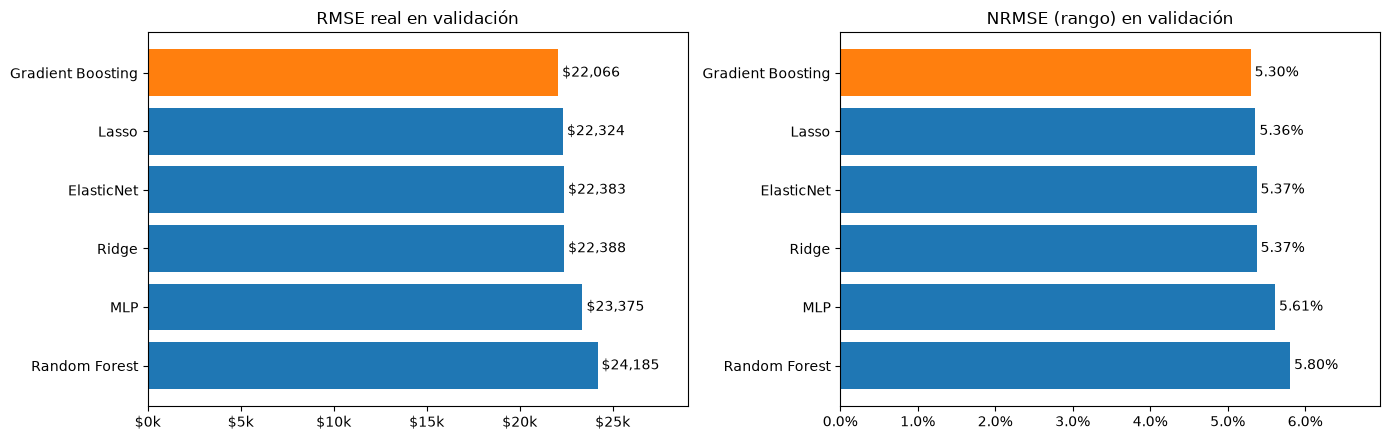

In [9]:
colores = ["tab:orange" if m == ganador else "tab:blue" for m in torneo["modelo"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].barh(torneo["modelo"], torneo["rmse_valid"], color=colores)
axes[0].xaxis.set_major_formatter(formato_dolares)
axes[0].set_title("RMSE real en validación")
for i, v in enumerate(torneo["rmse_valid"]):
    axes[0].text(v, i, f" ${v:,.0f}", va="center")

axes[1].barh(torneo["modelo"], torneo["nrmse_valid"], color=colores)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.1%}"))
axes[1].set_title("NRMSE (rango) en validación")
for i, v in enumerate(torneo["nrmse_valid"]):
    axes[1].text(v, i, f" {v:.2%}", va="center")

for ax in axes:
    ax.invert_yaxis()
    ax.margins(x=0.2)

plt.tight_layout()
plt.show()

## Diagnóstico de cada modelo en validación

Para cada modelo (en el orden del torneo), en dólares:

- **Real vs. predicho:** los puntos deben caer sobre la diagonal; una curvatura indica sesgo en precios altos o bajos.
- **Residuos vs. predicho:** deben distribuirse alrededor de 0 sin patrón; un embudo indica que el error crece con el precio.
- **Histograma de residuos:** idealmente centrado en 0 y simétrico.

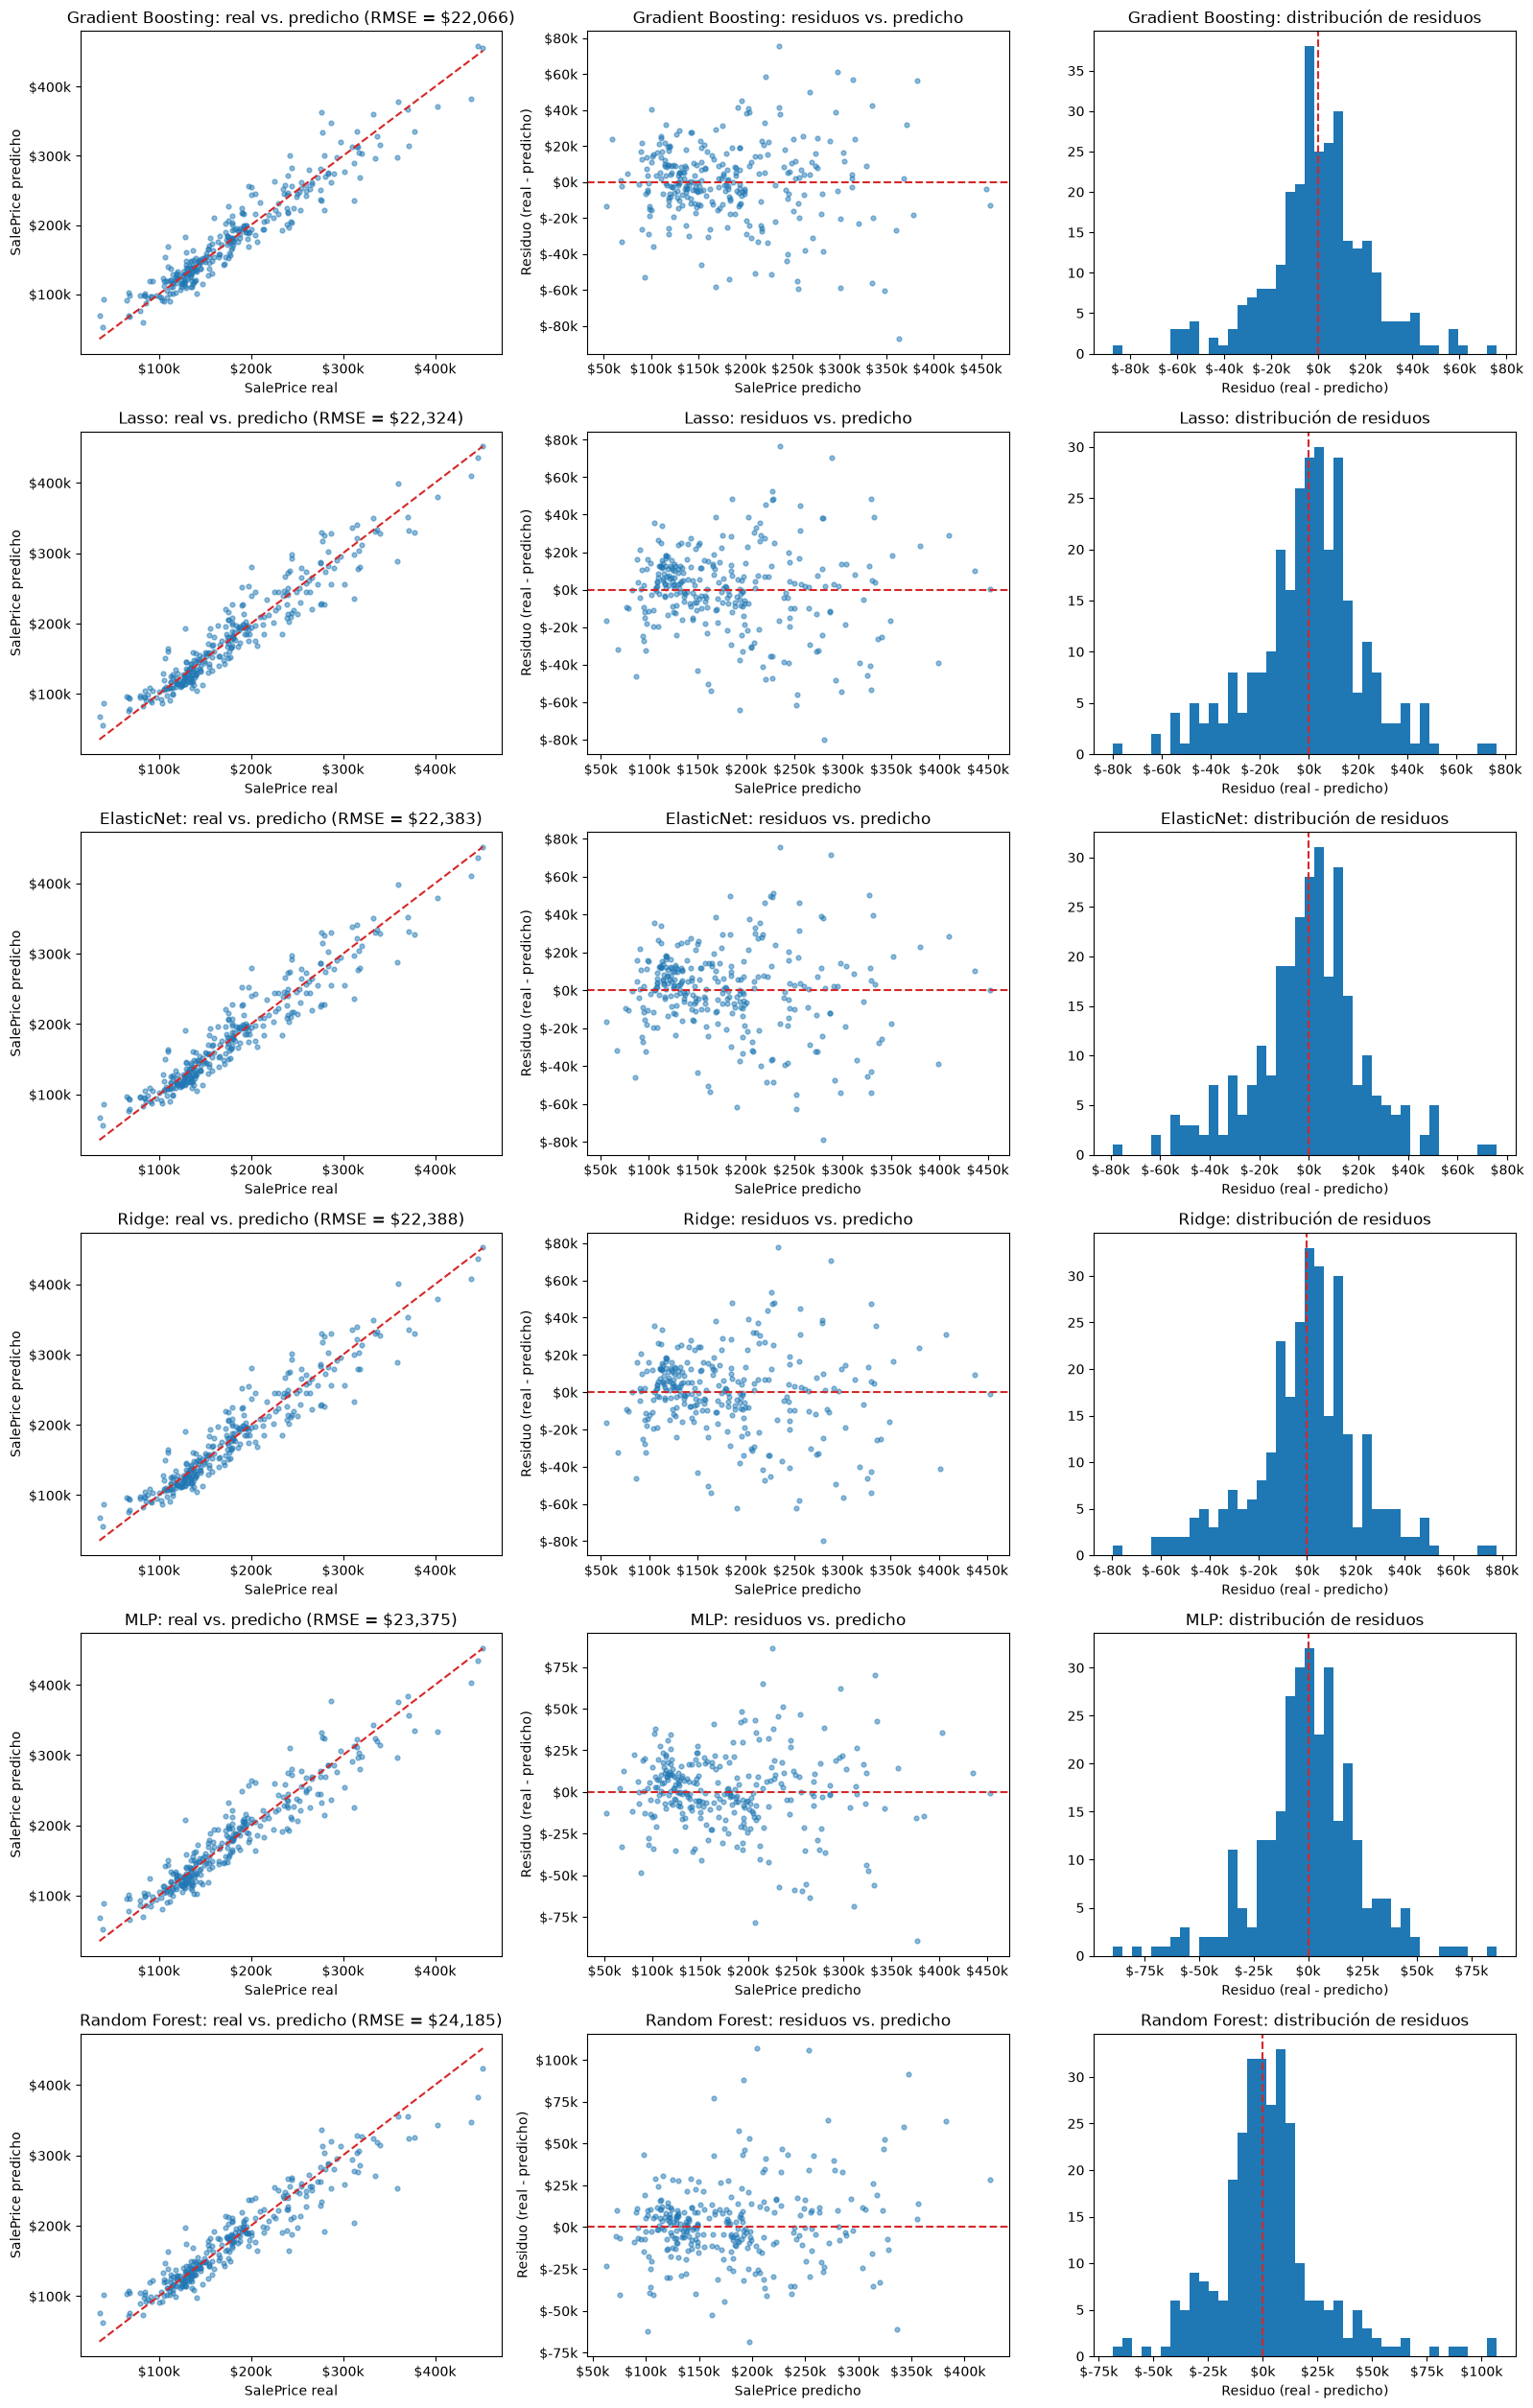

In [10]:
fig, axes = plt.subplots(len(torneo), 3, figsize=(16, 4.2 * len(torneo)))
limites = [y_valid_real.min(), y_valid_real.max()]

for fila, nombre in zip(axes, torneo["modelo"]):
    pred = predicciones[nombre]
    residuos = y_valid_real - pred
    rmse = torneo.set_index("modelo").loc[nombre, "rmse_valid"]

    fila[0].scatter(y_valid_real, pred, alpha=0.5, s=12)
    fila[0].plot(limites, limites, color="tab:red", linestyle="--")
    fila[0].set_title(f"{nombre}: real vs. predicho (RMSE = ${rmse:,.0f})")
    fila[0].set_xlabel("SalePrice real")
    fila[0].set_ylabel("SalePrice predicho")

    fila[1].scatter(pred, residuos, alpha=0.5, s=12)
    fila[1].axhline(0, color="tab:red", linestyle="--")
    fila[1].set_title(f"{nombre}: residuos vs. predicho")
    fila[1].set_xlabel("SalePrice predicho")
    fila[1].set_ylabel("Residuo (real - predicho)")

    fila[2].hist(residuos, bins=40)
    fila[2].axvline(0, color="tab:red", linestyle="--")
    fila[2].set_title(f"{nombre}: distribución de residuos")
    fila[2].set_xlabel("Residuo (real - predicho)")

    fila[0].xaxis.set_major_formatter(formato_dolares)
    fila[0].yaxis.set_major_formatter(formato_dolares)
    fila[1].xaxis.set_major_formatter(formato_dolares)
    fila[1].yaxis.set_major_formatter(formato_dolares)
    fila[2].xaxis.set_major_formatter(formato_dolares)

plt.tight_layout()
plt.show()

## Guardado del modelo ganador

Construye el pipeline completo de inferencia con el modelo ganador del torneo y lo guarda en `models/modelo_ganador.joblib`. El pipeline recibe los **datos crudos** (todas las columnas de `train.csv`/`test.csv`) y devuelve el precio en **dólares**:

1. `seleccion_features` (`DropFeatures`): descarta las columnas que no están en `MODEL_FEATURES`.
2. `fe`: el pipeline de feature engineering del notebook 2.0, sin ajustar (imputación, codificación, capping, Yeo-Johnson y escalado).
3. `modelo`: el estimador ganador con sus mejores hiperparámetros de la búsqueda.
4. `TransformedTargetRegressor`: aplica `log1p` al target al entrenar y `expm1` a las predicciones, para que la salida quede en dólares.

Como el modelo y sus hiperparámetros ya quedaron elegidos con la CV y el torneo, se reentrena con **train + validación** (1,458 casas) para aprovechar todos los datos disponibles. El feature engineering se reajusta con ese mismo conjunto, dentro del pipeline.

In [11]:
from feature_engine.selection import DropFeatures

X_completo = train.loc[pd.concat([ids_train, ids_valid]), :].drop(columns="SalePrice")
y_completo = train.loc[X_completo.index, "SalePrice"]

modelo_ganador = TransformedTargetRegressor(
    regressor=Pipeline([
        ("seleccion_features", DropFeatures(features_to_drop=[c for c in X_completo.columns if c not in MODEL_FEATURES])),
        ("fe", clone(pipeline_fe)),
        ("modelo", clone(busquedas[ganador].best_estimator_.named_steps["modelo"])),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)
modelo_ganador.fit(X_completo, y_completo)

joblib.dump(modelo_ganador, MODELS_DIR / "modelo_ganador.joblib")

print(f"Modelo ganador: {ganador}")
print(f"Hiperparámetros: {busquedas[ganador].best_params_}")
print(f"Entrenado con: {X_completo.shape}")
print(f"Guardado en: {(MODELS_DIR / 'modelo_ganador.joblib').relative_to(PROJ_ROOT)}")
modelo_ganador

Modelo ganador: Gradient Boosting
Hiperparámetros: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
Entrenado con: (1458, 79)
Guardado en: models/modelo_ganador.joblib


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...sample=0.8))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0",list,"['MS...ss', 'MS...ng', 'Lo...ge', 'LotArea', ...]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...sample=0.8))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion_features', ...), ('fe', ...), ...]"
